# Atera 空间可视化 — 整体图、6 个圆形 ROI 与物理比例尺

本 notebook 用一份**原始 Atera 乳腺癌数据**（WTA Breast Cancer FFPE、DCIS）走完一条出图链路：

1. **读取**：从 Atera 原始输出目录直接读，包括它自己的 `cell_groups.csv` 聚类
2. **整体图**：`total_counts` 与 `cell_group` 两张**点图**（squidpy），不用细胞轮廓
3. **选 6 个 ROI**：2 行 × 3 列、整齐对齐在切片上，每个 ROI 是一个「圆心 + 物理半径」的圆
4. **逐个 ROI**：6 个 panel 用相同视野，cluster 点图直接可比较
5. **缩小半径**：半径缩到 100 µm，改画**细胞轮廓**（cluster）
6. **换成基因表达**：同一批细胞上画 11q13 扩增子里表达最高的基因

每张图都带**物理比例尺**，长度随视野自动变化：整体图 1000 µm、ROI 图 50 µm、细胞级 50 µm。

需要 `trackcell >= 0.4.8`（`spatial_cell(frameon=...)` 与「`uns['<col>_colors']` 自动配色」
从 0.4.7 起，`read_atera()` 直接按 scanpy 约定写配色从 0.4.8 起），以及 `squidpy`
（点图用）与 `scanpy`。

数据目录默认指向本机路径，也可以用环境变量 `ATERA_DATA` 覆盖，指向包含 `breast_preview/`
的那个 run 目录。


In [1]:
import os
import time
import warnings
from pathlib import Path

# 只压掉这几类已知噪音，不要 blanket ignore —— 真正的告警（比如配色长度对不上）
# 必须能看见，否则图会悄悄换色。
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.patches import Patch

import trackcell as tcl
import squidpy as sq

# 一个 ROI bundle = Atera 的一次输出。必须是 Path：后面要 ROI_DIR / "gene_groups.csv"
ROI_DIR = "/Volumes/data/co_project/RD/atera/data/breast_preview"

plt.rcParams["figure.dpi"] = 100
print("trackcell :", tcl.__version__)

trackcell : 0.4.9


## 1. 从原始 Atera 数据读取

`tcl.io.read_atera()` 自动识别格式。

preview 数据是 Xenium-v4 兼容的
`cell_feature_matrix.h5` + `cells.parquet` + `cell_boundaries.parquet`，
官方数据是 AnnData Zarr + `cells.zarr`，两种读出来结构一致。

`cell_groups.csv` 是 Atera 自己给出的单细胞聚类（这里是 19 个群，含 11q13 扩增的
DCIS 亚群），会被读成 `obs['cell_group']`，配色放在
`uns['cell_group_colors']` —— 所以下面所有图用的都是厂商原始分类，不是我又重新聚的。

读 17 万细胞 + 多边形大约 1 分钟。

In [2]:
t0 = time.time()
adata = tcl.io.read_atera(
    ROI_DIR,
    sample="breast",
    build_polygons=True,        # 最后一步要画细胞轮廓
    include_nucleus=False,      # 不用核多边形，省一半构建时间
    verbose=False,
)

display(f"read {adata.n_obs:,} cells × {adata.n_vars:,} genes in {time.time() - t0:.0f}s")

# 有 12 个细胞不属于任何 cell_group：先剔掉。布尔索引出来的是 view，
# 必须 .copy() —— 后面还要往 obs 里写列（log1p、基因表达），
# 在 view 上写会触发 ImplicitModificationWarning，也可能写不回原对象。
adata = adata[adata.obs["cell_group"].notna()].copy()

display(adata.shape)
display(adata.var.head(2))
display(adata.obs.head(2))

'read 170,057 cells × 27,104 genes in 44s'

(170045, 27104)

,gene_ids,feature_types,is_gene_expression
gene_symbol,,,
A1BG,ENSG00000121410,Gene Expression,True
A1CF,ENSG00000148584,Gene Expression,True


,x_centroid,y_centroid,cell_area,nucleus_area,transcript_counts,total_counts,nucleus_count,control_probe_counts,genomic_control_counts,control_codeword_counts,unassigned_codeword_counts,segmentation_method,barcode,cell_group
barcode,,,,,,,,,,,,,,
aaaajgij-1,74.006966,2732.648438,81.184986,60.775857,5508,5513,1,0,4,1,0,Segmented by boundary stain (ATP1A1+CD45+E-Cad...,aaaajgij-1,Luminal-like Amorphous DCIS Cells
aaaandia-1,152.945572,2721.637939,113.785408,85.429362,6522,6527,1,0,5,0,0,Segmented by boundary stain (ATP1A1+CD45+E-Cad...,aaaandia-1,Luminal-like Amorphous DCIS Cells


In [3]:
coords = np.asarray(adata.obsm["spatial"])
span = np.ptp(coords, axis=0)

print(f"切片范围              : {span[0]:.0f} × {span[1]:.0f} µm")
print(f"cell_group           : {adata.obs['cell_group'].nunique()} 群, "
      f"未分配 {int(adata.obs['cell_group'].isna().sum())} 个细胞")

切片范围              : 9879 × 5940 µm
cell_group           : 19 群, 未分配 0 个细胞


配色直接来自 Atera 的 `cell_groups.csv`。`read_atera()` 已经把它写成 scanpy / squidpy
约定的形式：`uns['cell_group_colors']` 是 **list**，顺序与
`obs['cell_group'].cat.categories` 一致；原始 `{群: hex}` 映射另存在
`uns['atera_cell_group_palette']` 里，方便按名字查。

这样 squidpy 和 `tcl.pl.spatial_cell()` 都会自动用这套 19 色，不必再传 `palette=`；
而且做 subset 时 AnnData 会把颜色 list 和 `cat.categories` 一起裁，ROI 子图里同一个群
仍然是同一个颜色。


In [4]:
adata.obs["log1p_total_counts"] = np.log1p(adata.obs["total_counts"].astype(float))
adata.obs[["total_counts", "log1p_total_counts"]].describe().loc[["mean", "50%", "max"]].round(2)

,total_counts,log1p_total_counts
mean,2950.57,7.59
50%,2118.00,7.66
max,26103.00,10.17


In [5]:
CATS = list(adata.obs["cell_group"].cat.categories)
COLORS = adata.uns["atera_cell_group_palette"]     # {群: hex}，按名字查用
CLUSTER_CMAP = ListedColormap(adata.uns["cell_group_colors"])

print(f"{len(CATS)} 群，配色 {len(adata.uns['cell_group_colors'])} 色")


19 群，配色 19 色


## 2. 整体 spatial 图：`total_counts` 与 cluster

整体图用**点图**（squidpy `spatial_scatter`）就够了：17 万个细胞画轮廓既慢又糊。
第一张是测序深度，第二张是 Atera 自己的聚类 —— 两张分开画，各自 6 × 3.4 in，
图例放在图外，方便单独插进文档。

比例尺由 `tcl.pl.add_scale_bar()` 画 —— 它接受任何 matplotlib 坐标轴，所以
squidpy 的图也能加。切片 9.9 mm 宽，自动比例尺给 1000 µm。


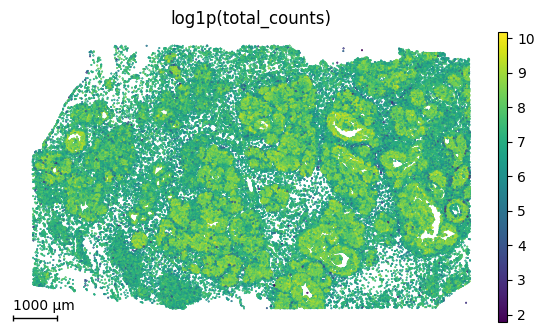

In [6]:
fig, ax = plt.subplots(1, 1, figsize=(6, 3.4))

sq.pl.spatial_scatter(
    adata, 
    library_id="breast", 
    color="log1p_total_counts", 
    shape=None, 
    size=1,
    ax=ax, 
    frameon=False,
    title="log1p(total_counts)"
)

ax.set_aspect("equal")
## 添加 scale bar
tcl.pl.add_scale_bar(ax, adata, library_id="breast", loc="lower left", linewidth=1)

fig.tight_layout()
plt.show()

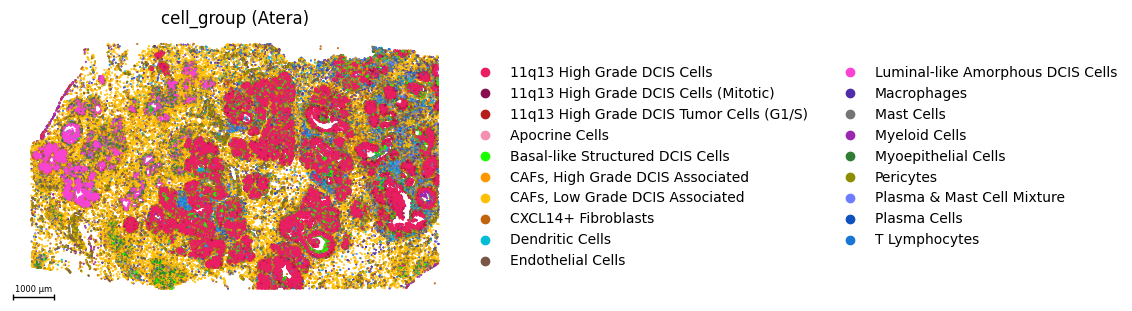

In [7]:
fig, ax = plt.subplots(1, 1, figsize=(6, 3.5))

sq.pl.spatial_scatter(
    adata, 
    library_id="breast", 
    color="cell_group", 
    shape=None, 
    size=1,
    frameon=False,
    #palette=CLUSTER_CMAP, 
    ax=ax, 
    title="cell_group (Atera)"
)

ax.set_aspect("equal")
## 添加 scale bar
tcl.pl.add_scale_bar(ax, adata, library_id="breast", loc="lower left", linewidth=1, fontsize=6)

fig.tight_layout()
plt.show()

## 3. 选 6 个 ROI：2 行 × 3 列，整齐对齐

ROI 用「圆心 + 物理半径」定义，不用手绘多边形：可以写进方法学段落，也可以在别的样本上
原样重跑。把切片外接框切成 **2 行 × 3 列** 六个格子，每个圆心的位置取该格子里细胞坐标的
**中位数** —— 这样 6 个圆既保持规整的两行三列，又不会落在没有组织的空白处
（直接取格子几何中心时，左下角那个格子会空到只剩几十个细胞）。

半径取 300 µm：在 9.9 mm × 5.9 mm 的切片上互不重叠，每个 ROI 里有几百到一千多个细胞。


In [8]:
RADIUS = 300.0     # µm，ROI 半径
x_lo, y_lo = coords.min(axis=0)
x_hi, y_hi = coords.max(axis=0)

# 2 行 × 3 列六个格子，每个格子取细胞坐标中位数当圆心
x_edges = np.linspace(x_lo, x_hi, 4)
y_edges = np.linspace(y_lo, y_hi, 3)
centers = []
for row in range(2):
    for col in range(3):
        in_cell = (
            (coords[:, 0] >= x_edges[col]) & (coords[:, 0] < x_edges[col + 1])
            & (coords[:, 1] >= y_edges[row]) & (coords[:, 1] < y_edges[row + 1])
        )
        centers.append(tuple(float(v) for v in np.median(coords[in_cell], axis=0)))

roi_masks = [tcl.tl.cells_in_radius(adata, c, RADIUS) for c in centers]
inside = np.zeros(adata.n_obs, dtype=bool)
for m in roi_masks:
    inside |= m

summary = pd.DataFrame({
    "roi": [f"ROI{i}" for i in range(1, 7)],
    "center_x_um": [round(c[0]) for c in centers],
    "center_y_um": [round(c[1]) for c in centers],
    "cells": [int(m.sum()) for m in roi_masks],
})
print(f"6 个 ROI 合计 {int(inside.sum()):,} 细胞；剩余组织 {int((~inside).sum()):,} 细胞")
summary

6 个 ROI 合计 7,314 细胞；剩余组织 162,731 细胞


,roi,center_x_um,center_y_um,cells
0,ROI1,1765,2200,1360
1,ROI2,5116,1762,1200
2,ROI3,8291,1723,1533
3,ROI4,2096,4157,712
4,ROI5,4604,4436,1458
5,ROI6,8181,3999,1051


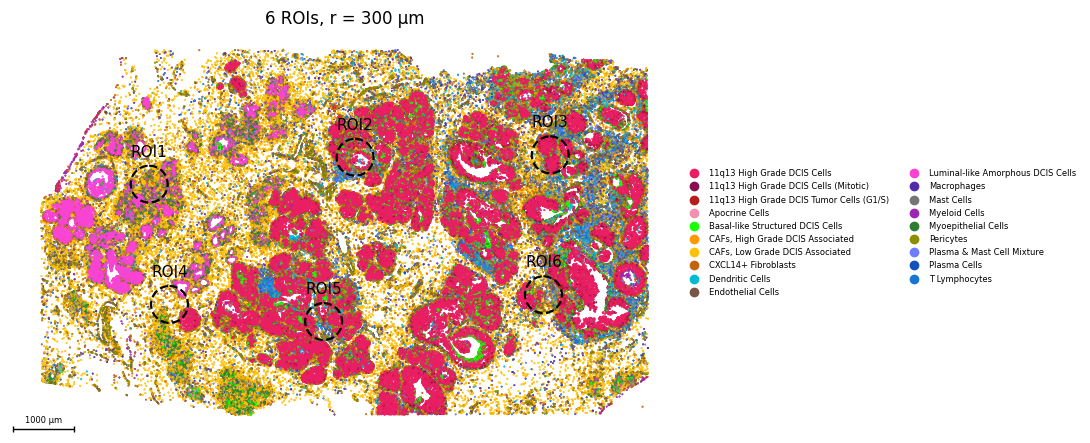

In [9]:
fig, ax = plt.subplots(figsize=(11, 10))
sq.pl.spatial_scatter(adata, 
                      library_id="breast", 
                      color="cell_group", 
                      shape=None,
                      size=1, 
                      frameon=False,
                      ax=ax, 
                      legend_fontsize=6,      # 缩小图例字体
                      title=f"6 ROIs, r = {RADIUS:.0f} µm")

for i, c in enumerate(centers, start=1):
    tcl.pl.mark_circle(ax, c, RADIUS, radius_unit="um", adata=adata,
                       edges_color="black", edges_width=1.6, linestyle="--", show=False)
    ax.text(c[0], c[1] - RADIUS - 110, f"ROI{i}", ha="center", va="bottom",
            fontsize=11, color="black", zorder=110)

ax.set_aspect("equal")
tcl.pl.add_scale_bar(ax, adata, library_id="breast", loc="lower left", linewidth=1, fontsize=6)

fig.tight_layout()
plt.show()

## 4. 逐个 ROI：6 个 panel，相同视野

同一套圆心、同一套配色，把 6 个 ROI 分 panel 画出来。每个 panel 都按
「圆心 ± 半径 × 1.06」锁定视野，所以 panel 之间可以直接比较细胞密度和群组成 ——
这是整体图上看不出来的。

比例尺统一 50 µm，对着 300 µm 的直径就能估尺度。


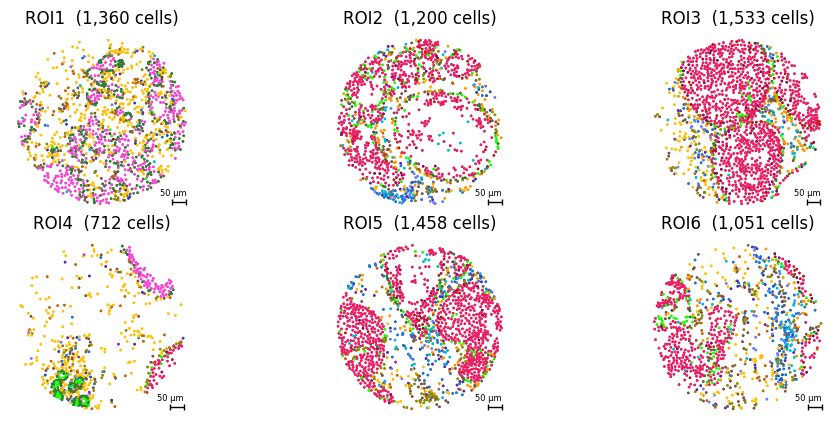

In [10]:
fig = plt.figure(figsize=(12, 5))
gs = fig.add_gridspec(2, 3, wspace=0.08, hspace=0.14)

for i, (center, mask) in enumerate(zip(centers, roi_masks)):
    ax = fig.add_subplot(gs[i // 3, i % 3])
    sq.pl.spatial_scatter(adata[mask].copy(), library_id="breast", color="cell_group",
                          shape=None, size=6, ax=ax, frameon=False, 
                          legend_loc=None, title=f"ROI{i + 1}  ({int(mask.sum()):,} cells)")
    
    ax.set_aspect("equal")
    tcl.pl.add_scale_bar(ax, adata, library_id="breast", length="50um",
                         loc="lower right", linewidth=1, fontsize=6, frame=True)

plt.show()

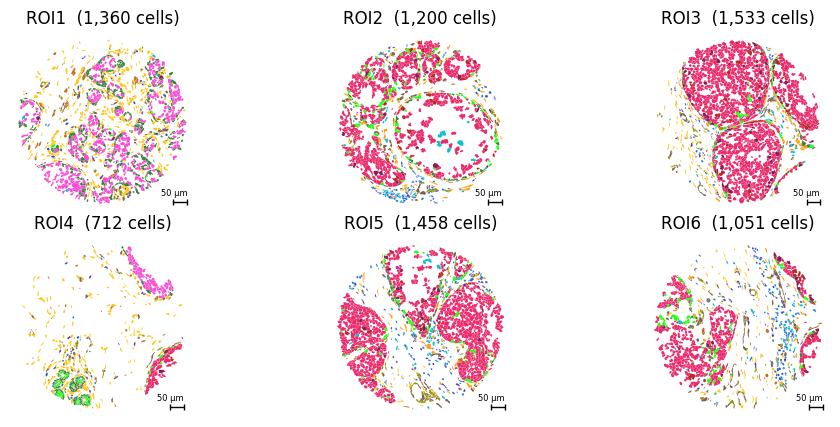

In [11]:
fig = plt.figure(figsize=(12, 5))
gs = fig.add_gridspec(2, 3, wspace=0.08, hspace=0.14)

for i, (center, mask) in enumerate(zip(centers, roi_masks)):
    ax = fig.add_subplot(gs[i // 3, i % 3])
    
    tcl.pl.spatial_cell(
        adata[mask].copy(), 
        library_id="breast", 
        color="cell_group", 
        frameon=False,
        edges_width=0, alpha=0.95, legend=False, show=False, ax=ax,
        scalebar=dict(length="50um", loc="lower right", linewidth=1,
                      fontsize=6, frame=True),
    )
    
    ax.set_title(f"ROI{i + 1}  ({int(mask.sum()):,} cells)")
    ax.set_aspect("equal")

plt.show()

## 5. 缩小半径：改画细胞轮廓

同 6 个圆心，半径从 300 µm 缩到 100 µm（每个 ROI 几十到两百多个细胞），
这时轮廓图才有意义 —— `tcl.pl.spatial_cell()` 直接用 `cells.zarr` /
`cell_boundaries.parquet` 里的多边形，不是圆点。

先看 cluster：颜色仍是 Atera 那 19 个群、那套配色。

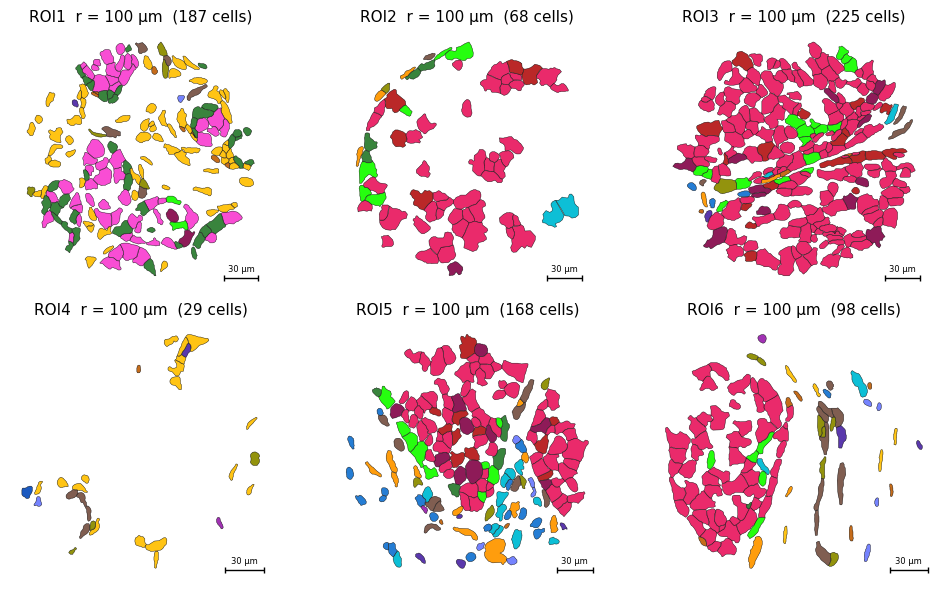

In [12]:
ZOOM = 100.0       # µm，缩小后的半径

fig, axes = plt.subplots(2, 3, figsize=(10, 6))
for i, center in enumerate(centers):
    ax = axes[i // 3, i % 3]
    mask = tcl.tl.cells_in_radius(adata, center, ZOOM)
    tcl.pl.spatial_cell(
        adata[mask].copy(), 
        color="cell_group", 
        frameon=False,
        edges_width=0.3, alpha=0.95, legend=False, show=False, ax=ax,
        scalebar=dict(length="30um", loc="lower right", linewidth=1,
                      fontsize=6, frame=True),
    )
    ax.set_title(f"ROI{i + 1}  r = {ZOOM:.0f} µm  ({int(mask.sum())} cells)", fontsize=11)
    
fig.tight_layout()
plt.show()

## 6. 换成基因表达：11q13 扩增子

同一批细胞，换成基因表达。这里画 `CCND1` —— 它就在 Atera `gene_groups.csv` 里标出的
11q13 扩增子内，是这个 DCIS 病例里表达最高的扩增基因，正好能看出哪些导管上皮带着扩增。

（`gene_groups.csv` 里的基因清单可以用 `pd.read_csv(ROI_DIR / "gene_groups.csv")` 自查。）

CCND1: p50=3  p99=126  max=512


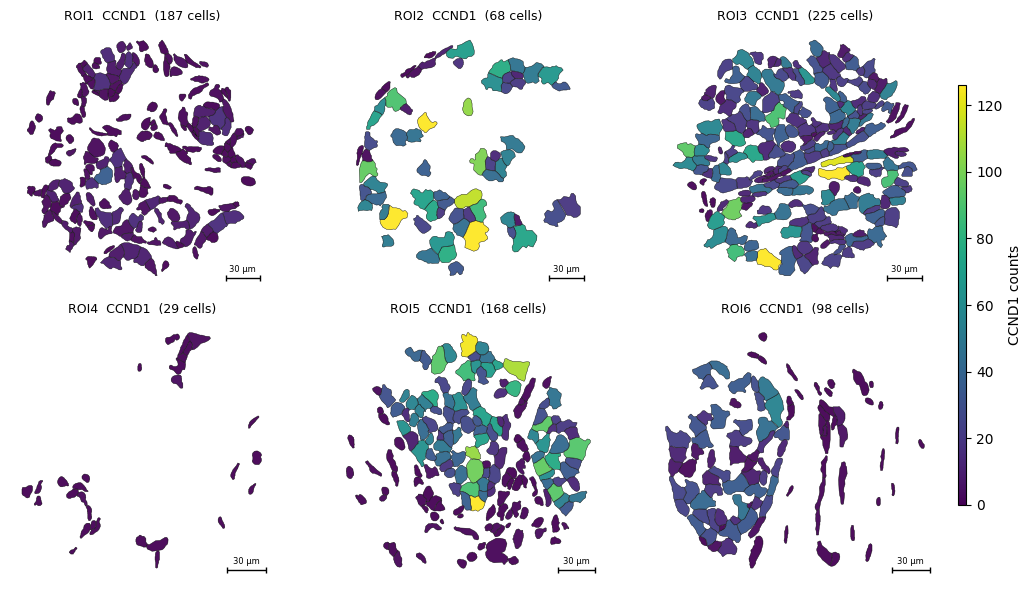

In [13]:
ZOOM = 100.0       # µm，缩小后的半径
GENE = "CCND1"

# 6 个 panel 要在同一色标下才可比：vmin/vmax 用整个切片算，不要每个 ROI 各自归一化
_gene_vec = adata[:, GENE].X
_gene_vec = _gene_vec.toarray().ravel() if hasattr(_gene_vec, "toarray") else np.asarray(_gene_vec).ravel()
VMAX = float(np.percentile(_gene_vec, 99))
print(f"{GENE}: p50={np.median(_gene_vec):.0f}  p99={VMAX:.0f}  max={_gene_vec.max():.0f}")

fig, axes = plt.subplots(2, 3, figsize=(10, 6))
for i, center in enumerate(centers):
    ax = axes[i // 3, i % 3]
    mask = tcl.tl.cells_in_radius(adata, center, ZOOM)
    tcl.pl.spatial_cell(
        adata[mask].copy(),
        color=GENE,
        cmap="viridis", vmin=0.0, vmax=VMAX,     # 固定色标
        frameon=False,
        edges_width=0.3, alpha=0.95, legend=False, show=False, ax=ax,
        scalebar=dict(length="30um", loc="lower right", linewidth=1,
                      fontsize=6, frame=True),
    )
    ax.set_title(f"ROI{i + 1}  {GENE}  ({int(mask.sum())} cells)", fontsize=9)

fig.tight_layout()
# 共用一根 colorbar
cax = fig.add_axes([0.99, 0.15, 0.008, 0.7])
fig.colorbar(ScalarMappable(norm=Normalize(0, VMAX), cmap="viridis"), cax=cax,
             label=f"{GENE} counts")
plt.show()


## 7. 比例尺速查

| 参数 | 说明 |
|---|---|
| `scalebar=True` | 自动长度：可见宽度的 ~18%，取 1/2/5×10ⁿ µm |
| `scalebar="50um"` | 定长（也接受 `100 µm`、`20px`） |
| `loc` | `lower right` / `upper left` / `center right` … |
| `offset` / `pad` | 额外位移（点）/ 轴内缩（轴分数） |
| `linewidth` / `fontsize` / `color` / `alpha` | 线宽、字号、颜色、透明度 |
| `caps` / `cap_size` | 端点短竖线 |
| `label` / `label_position` | 文字内容 / `auto`、`above`、`below`、`none` |
| `frame` | H&E 背景上的衬底框 |
| `microns_per_unit` | 覆盖单位推断（无 scalefactors 的像素坐标） |

比例尺在被裁剪进框内：连端点、文字、衬底框一起算，**而且**在
`tight_layout()` / `savefig(bbox_inches="tight")` / 窗口缩放之后重新摆位，
所以不会压到 axes 边框上，也不会被裁掉。

`tcl.pl.add_scale_bar()` 也能单独用在任何 matplotlib 轴上（本页的 squidpy 点图就是这样加的）：

```python
info = tcl.pl.add_scale_bar(ax, adata, length="1000um", loc="lower right")
# {'length': 1000.0, 'label': '1000 µm', 'axes_fraction': 0.10, ...}
```

## 小结

* Atera 原始输出直接读：矩阵 + 多边形 + 厂商自己的 `cell_groups.csv` 聚类
* 整体图用点图就够（`total_counts` / `cluster` 各一张），ROI 与细胞级才上轮廓
* ROI 用「圆心 + 物理半径」定义：`tl.cells_in_radius()`，可复现、可报告、可换样本重跑
* 6 个 ROI 排成 2 × 3，既能整体对照看，也能单独放大看
* 半径 300 µm → 100 µm，同一圆心从 cluster 点图切到细胞轮廓，再换基因表达
* 比例尺长度跟着视野走（1000 / 100 / 50 µm），且始终留在框内

延伸阅读：

* :doc:`../usage/atera` — Atera 读取、多边形、单分子点云、QC
* :doc:`../usage/visualization` — 比例尺、圆形 ROI、双色叠加、交互式选区